In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

df = pd.read_csv("../../processed/df_preproc.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Outcome labels
status_labels = {
    1: "Status 1",
    2: "Status 2",
    3: "Status 3",
    4: "EP Sent",
    5: "EP Confirmed",
    6: "EP Received",
    7: "Closed"
}

# ------------------------------------------------------------
# Weekly aggregation
# ------------------------------------------------------------

df["Week"] = df["Date"].dt.to_period("W-SUN").apply(
    lambda x: x.start_time
)

weekly = df.groupby("Week").size().rename("Total").to_frame()

for status in range(1, 8):
    weekly[f"Status {status}"] = (
        df.assign(
            indicator=df["CallStatusNo"].eq(status)
        )
        .groupby("Week")["indicator"]
        .sum()
    )

weekly = weekly.fillna(0)

# ------------------------------------------------------------
# Monthly aggregation
# ------------------------------------------------------------

df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()

monthly = df.groupby("Month").size().rename("Total").to_frame()

for status in range(1, 8):
    monthly[f"Status {status}"] = (
        df.assign(
            indicator=df["CallStatusNo"].eq(status)
        )
        .groupby("Month")["indicator"]
        .sum()
    )

monthly = monthly.fillna(0)

# ------------------------------------------------------------
# Plotting helper
# ------------------------------------------------------------

status_columns = [f"Status {i}" for i in range(1, 8)]

def stacked_counts(data, filename, title):
    fig, ax = plt.subplots(figsize=(12, 6))

    bottom = np.zeros(len(data))

    for status in range(1, 8):
        col = f"Status {status}"

        ax.bar(
            data.index,
            data[col],
            bottom=bottom,
            width=5 if len(data) > 10 else 20,
            label=status_labels[status]
        )

        bottom += data[col].to_numpy()

    ax.set_title(title)
    ax.set_ylabel("Number of leads")
    ax.set_xlabel("Date")
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        frameon=False
    )

    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.close(fig)


def stacked_proportions(data, filename, title):
    proportions = data[status_columns].div(
        data["Total"], axis=0
    )

    fig, ax = plt.subplots(figsize=(12, 6))

    bottom = np.zeros(len(data))

    for status in range(1, 8):
        col = f"Status {status}"

        ax.bar(
            data.index,
            proportions[col],
            bottom=bottom,
            width=5 if len(data) > 10 else 20,
            label=status_labels[status]
        )

        bottom += proportions[col].to_numpy()

    ax.set_title(title)
    ax.set_ylabel("Proportion of leads")
    ax.set_xlabel("Date")
    ax.set_ylim(0, 1)

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        frameon=False
    )

    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.close(fig)


# ------------------------------------------------------------
# Generate the four figures
# ------------------------------------------------------------

stacked_counts(
    weekly,
    "weekly_outcome_counts.png",
    "Weekly Counts of Lead Outcomes"
)

stacked_proportions(
    weekly,
    "weekly_outcome_proportions.png",
    "Weekly Proportions of Lead Outcomes"
)

stacked_counts(
    monthly,
    "monthly_outcome_counts.png",
    "Monthly Counts of Lead Outcomes"
)

stacked_proportions(
    monthly,
    "monthly_outcome_proportions.png",
    "Monthly Proportions of Lead Outcomes"
)

print("Figures generated successfully.")

Figures generated successfully.


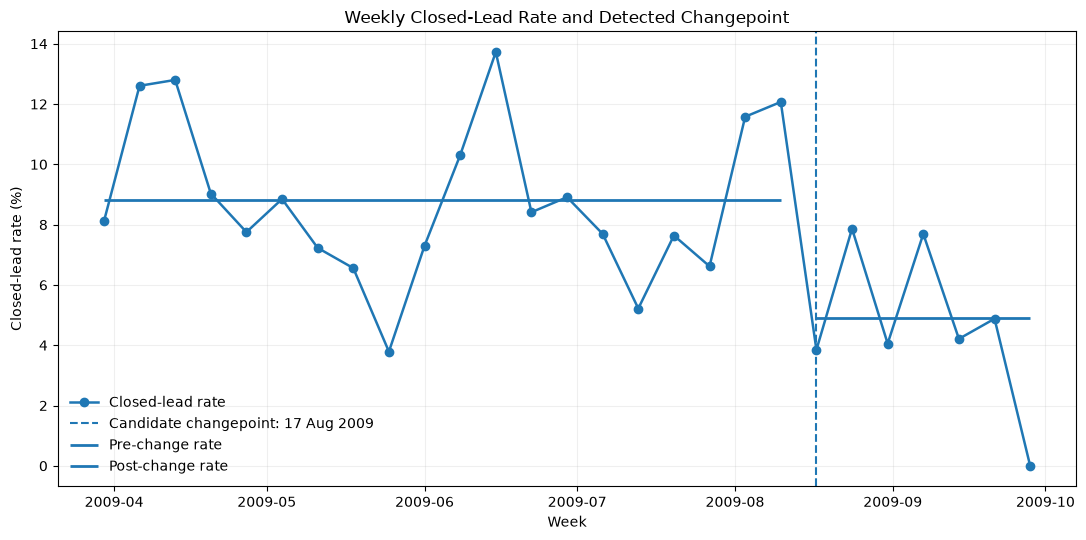

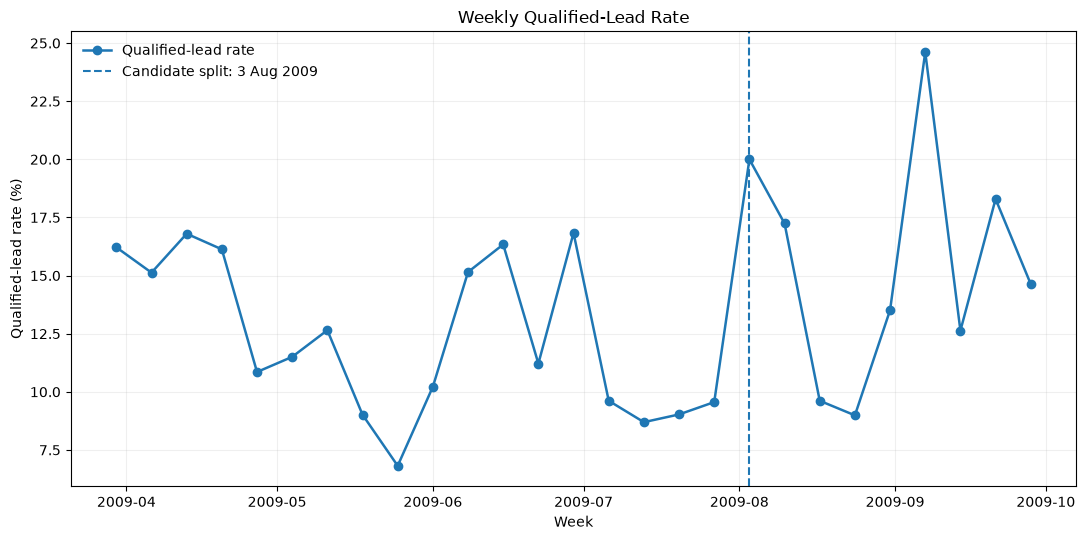

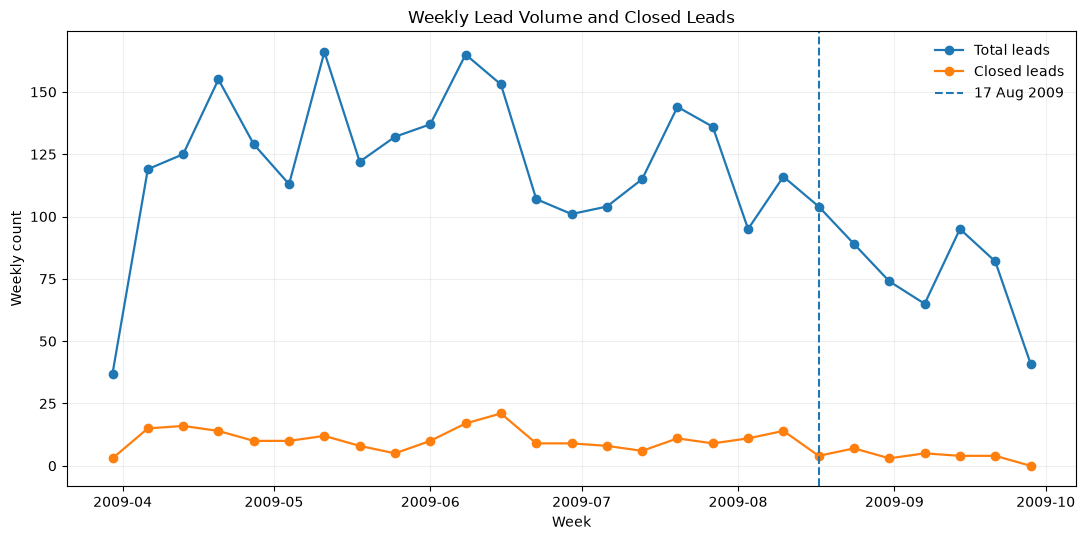

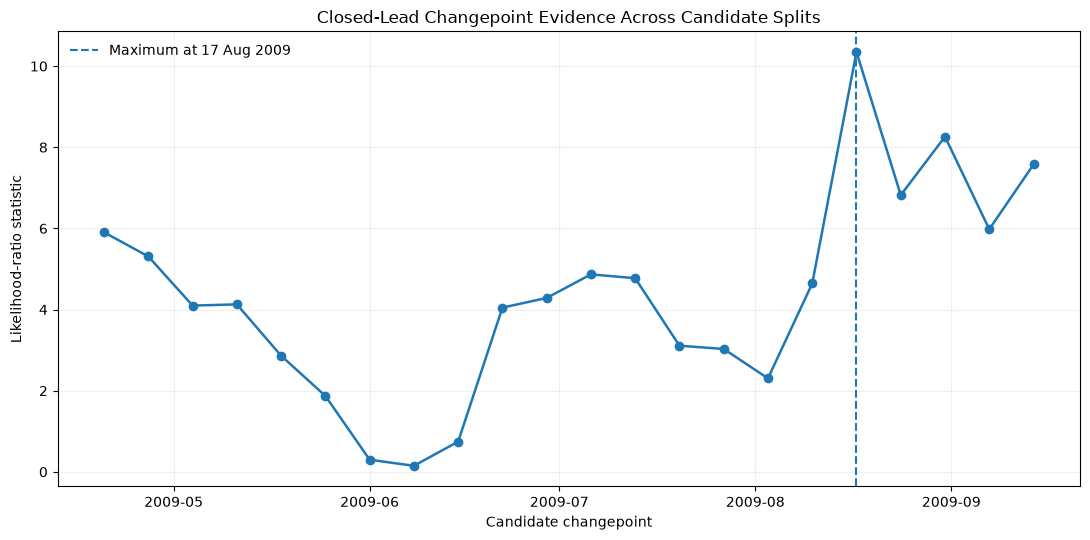

Detected candidate changepoint: 17 August 2009
Maximum likelihood-ratio statistic: 10.347


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2
from pathlib import Path

# Load the cleaned dataset
path = "../../processed/df_preproc.csv"
df = pd.read_csv(path)

# Find the date column robustly
date_candidates = [c for c in df.columns if c.lower() in
                   {"date", "lead_date", "created_date", "created", "datetime", "timestamp"}]

if not date_candidates:
    raise ValueError(f"Could not identify the date column. Columns are: {list(df.columns)}")

date_col = date_candidates[0]
df[date_col] = pd.to_datetime(df[date_col])

# Definitions used in the report
df["Qualified"] = df["CallStatusNo"].isin([4, 5, 6, 7])
df["Closed"] = df["CallStatusNo"].eq(7)

# Weekly data
df["Week"] = df[date_col].dt.to_period("W-SUN").apply(lambda x: x.start_time)

weekly = df.groupby("Week").agg(
    n=("CallStatusNo", "size"),
    qualified=("Qualified", "sum"),
    closed=("Closed", "sum")
).reset_index()

weekly["qualified_rate"] = weekly["qualified"] / weekly["n"]
weekly["closed_rate"] = weekly["closed"] / weekly["n"]

# Candidate changepoint from the analysis
cp_date = pd.Timestamp("2009-08-17")
weekly["period"] = np.where(weekly["Week"] < cp_date, "Before", "After")

# ------------------------------------------------------------
# 1. Weekly closed-lead rate with changepoint
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.plot(
    weekly["Week"],
    100 * weekly["closed_rate"],
    marker="o",
    linewidth=1.8,
    label="Closed-lead rate"
)

ax.axvline(
    cp_date,
    linestyle="--",
    linewidth=1.5,
    label="Candidate changepoint: 17 Aug 2009"
)

before = weekly[weekly["Week"] < cp_date]
after = weekly[weekly["Week"] >= cp_date]

ax.hlines(
    100 * before["closed"].sum() / before["n"].sum(),
    before["Week"].min(),
    before["Week"].max(),
    linewidth=2,
    label="Pre-change rate"
)

ax.hlines(
    100 * after["closed"].sum() / after["n"].sum(),
    after["Week"].min(),
    after["Week"].max(),
    linewidth=2,
    label="Post-change rate"
)

ax.set_ylabel("Closed-lead rate (%)")
ax.set_xlabel("Week")
ax.set_title("Weekly Closed-Lead Rate and Detected Changepoint")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    "changepoint_closed_rate.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 2. Weekly qualified-lead rate with candidate changepoint
# ------------------------------------------------------------

# Candidate split used in the report for the qualified rate
qualified_cp = pd.Timestamp("2009-08-03")

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.plot(
    weekly["Week"],
    100 * weekly["qualified_rate"],
    marker="o",
    linewidth=1.8,
    label="Qualified-lead rate"
)

ax.axvline(
    qualified_cp,
    linestyle="--",
    linewidth=1.5,
    label="Candidate split: 3 Aug 2009"
)

ax.set_ylabel("Qualified-lead rate (%)")
ax.set_xlabel("Week")
ax.set_title("Weekly Qualified-Lead Rate")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    "changepoint_qualified_rate.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 3. Counts with changepoint
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.plot(
    weekly["Week"],
    weekly["n"],
    marker="o",
    linewidth=1.6,
    label="Total leads"
)

ax.plot(
    weekly["Week"],
    weekly["closed"],
    marker="o",
    linewidth=1.6,
    label="Closed leads"
)

ax.axvline(
    cp_date,
    linestyle="--",
    linewidth=1.5,
    label="17 Aug 2009"
)

ax.set_ylabel("Weekly count")
ax.set_xlabel("Week")
ax.set_title("Weekly Lead Volume and Closed Leads")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    "changepoint_counts.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 4. Likelihood-ratio statistic over every possible split
# ------------------------------------------------------------

# Binomial likelihood-ratio statistic for a single split.
# This is much more appropriate for lead-quality proportions
# than applying a Gaussian changepoint statistic directly.

def binomial_loglik(y, n, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return np.sum(y * np.log(p) + (n - y) * np.log(1 - p))

y = weekly["closed"].to_numpy(dtype=float)
n = weekly["n"].to_numpy(dtype=float)

global_p = y.sum() / n.sum()
ll_null = binomial_loglik(y, n, global_p)

statistics = []
candidate_dates = []

# Avoid very short segments
min_segment = 3

for tau in range(min_segment, len(weekly) - min_segment + 1):

    p1 = y[:tau].sum() / n[:tau].sum()
    p2 = y[tau:].sum() / n[tau:].sum()

    ll_alt = (
        binomial_loglik(y[:tau], n[:tau], p1)
        + binomial_loglik(y[tau:], n[tau:], p2)
    )

    lr = 2 * (ll_alt - ll_null)

    statistics.append(lr)
    candidate_dates.append(weekly.loc[tau, "Week"])

statistics = np.asarray(statistics)
candidate_dates = pd.to_datetime(candidate_dates)

best_idx = np.argmax(statistics)
best_date = candidate_dates[best_idx]
best_stat = statistics[best_idx]

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.plot(
    candidate_dates,
    statistics,
    marker="o",
    linewidth=1.8
)

ax.axvline(
    best_date,
    linestyle="--",
    linewidth=1.5,
    label=f"Maximum at {best_date:%d %b %Y}"
)

ax.set_xlabel("Candidate changepoint")
ax.set_ylabel("Likelihood-ratio statistic")
ax.set_title("Closed-Lead Changepoint Evidence Across Candidate Splits")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    "changepoint_likelihood_ratio.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print(f"Detected candidate changepoint: {best_date:%d %B %Y}")
print(f"Maximum likelihood-ratio statistic: {best_stat:.3f}")
